# Stage 2 — Confidence-Aware Multimodal Mixture of Experts

**Project:** extend the Stage 1 YOLO MoE with calibrated routing confidence, an explicit clarification decision, and expert-output confidence checks.

This notebook builds on the first project:

- **Expert 0 — Classification:** your existing YOLO classification checkpoint.
- **Expert 1 — Segmentation:** your existing YOLO segmentation checkpoint.
- **Decision 2 — Clarify / abstain:** not a third expert. It is a safe routing decision used when the request is ambiguous or the gate is not confident enough.
- **Gate:** a CLIP-based image/text router initialized from the Stage 1 checkpoint and extended from two outputs to three.

## What changes in Stage 2?

Stage 1 always selected one of the two experts. Stage 2 can decline to dispatch when the prompt is ambiguous or the calibrated routing confidence is below a threshold.

After an expert runs, we also inspect its task-specific confidence:
- Classification: YOLO's top-1 class confidence.
- Segmentation: the highest instance/detection confidence, when an instance is found.

These expert scores are **not directly comparable across tasks**. They are used to flag an uncertain result, not to decide whether classification or segmentation is the correct task.

## Learning path

1. Configure the environment and device (macOS, Windows, Linux, or Colab).
2. Load the Stage 1 router and YOLO expert checkpoints.
3. Create examples for classification, segmentation, and ambiguous requests.
4. Expand the gate to three decisions and fine-tune it.
5. Calibrate its probabilities with temperature scaling.
6. Evaluate confidence, coverage, and abstention behavior.
7. Run confidence-aware inference and inspect expert confidence.
8. Save a portable Stage 2 checkpoint and configuration.

> **Before you start:** run Stage 1 at least once and make sure its `artifacts/` directory contains `router.pt`, `classification_best.pt`, and `segmentation_best.pt`. This notebook reuses the two YOLO experts; it does not retrain them.

## 1. Environment, operating system and compute device

The model code is shared across platforms. Only package installation, project storage, and hardware selection vary.

- **Google Colab:** select a GPU runtime if available. Google Drive mounting is optional.
- **Windows / Linux:** use a Python 3.10 or 3.11 virtual environment.
- **Apple Silicon Mac:** PyTorch may use MPS. If a specific operation is unsupported, use CPU for that operation.
- **NVIDIA GPU:** install a PyTorch build compatible with your CUDA setup using the official PyTorch installation selector.

The setup cell automatically selects CUDA, Apple MPS, or CPU. `NUM_WORKERS=0` is a conservative choice for notebook and Windows compatibility.

In [1]:
# Install dependencies in the active notebook environment.
# For a CUDA-specific PyTorch build, follow https://pytorch.org/get-started/locally/
%pip install -q open_clip_torch ultralytics opencv-python-headless torchvision matplotlib pillow scikit-learn

import os
import sys
import json
import random
import shutil
import platform
from pathlib import Path
from typing import List, Dict, Any, Optional, Tuple

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets
from PIL import Image
import matplotlib.pyplot as plt

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

if IN_COLAB:
    from google.colab import drive
    MOUNT_GOOGLE_DRIVE = True
    if MOUNT_GOOGLE_DRIVE:
        drive.mount("/content/drive")
        PROJECT_DIR = Path("/content/drive/MyDrive/yolo_moe_project")
    else:
        PROJECT_DIR = Path("/content/yolo_moe_project")
else:
    PROJECT_DIR = Path.cwd() / "yolo_moe_project"

DATA_DIR = PROJECT_DIR / "data"
RUNS_DIR = PROJECT_DIR / "runs"
ARTIFACT_DIR = PROJECT_DIR / "artifacts"
for folder in (PROJECT_DIR, DATA_DIR, RUNS_DIR, ARTIFACT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

NUM_WORKERS = 0
PIN_MEMORY = DEVICE.type == "cuda"

def get_ultralytics_device(device: torch.device):
    """Map a PyTorch device to the device argument accepted by Ultralytics.

    Input: torch.device('cuda'), torch.device('mps'), or torch.device('cpu').
    Output: 0 for CUDA's first GPU, 'mps' for Apple Silicon, or 'cpu'.
    """
    if device.type == "cuda":
        return 0
    if device.type == "mps":
        return "mps"
    return "cpu"

YOLO_DEVICE = get_ultralytics_device(DEVICE)

print("OS:", platform.platform())
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Colab:", IN_COLAB)
print("Selected device:", DEVICE)
print("Project directory:", PROJECT_DIR)
print("Stage 1 artifacts:", ARTIFACT_DIR)

Note: you may need to restart the kernel to use updated packages.
OS: macOS-26.5.2-arm64-arm-64bit-Mach-O
Python: 3.13.18
PyTorch: 2.15.0
Colab: False
Selected device: mps
Project directory: /Users/christy.manthara/repositories/MoE-cls-seg/yolo_moe_project
Stage 1 artifacts: /Users/christy.manthara/repositories/MoE-cls-seg/yolo_moe_project/artifacts


### Device-specific notes and artifact check

The notebook expects the Stage 1 files below. If you stored them elsewhere, change `ARTIFACT_DIR` in the setup cell.

| Platform | Device selection |
|---|---|
| Colab GPU | CUDA |
| Windows / Linux with NVIDIA GPU | CUDA |
| Apple Silicon Mac | MPS when supported |
| Intel Mac / CPU-only computer | CPU |

For a first test on a laptop, keep the router batch size small. The CLIP backbone is frozen, but it still needs memory and compute for feature extraction.

In [2]:
STAGE1_ROUTER_PATH = ARTIFACT_DIR / "router.pt"
CLS_WEIGHTS_PATH = ARTIFACT_DIR / "classification_best.pt"
SEG_WEIGHTS_PATH = ARTIFACT_DIR / "segmentation_best.pt"

required_stage1_files = [STAGE1_ROUTER_PATH, CLS_WEIGHTS_PATH, SEG_WEIGHTS_PATH]
missing = [str(p) for p in required_stage1_files if not p.exists()]
if missing:
    raise FileNotFoundError(
        "Missing Stage 1 artifact(s):\\n" + "\\n".join(missing) +
        "\\nRun Stage 1 first, or copy the three files into ARTIFACT_DIR."
    )
print("All Stage 1 checkpoints found.")

All Stage 1 checkpoints found.


## 2. Define the three routing decisions

The gate now has three outputs:

| ID | Decision | Meaning |
|---:|---|---|
| 0 | `classification` | Call the YOLO classification expert |
| 1 | `segmentation` | Call the YOLO segmentation expert |
| 2 | `clarify` | Do not call either expert; ask for a clearer instruction |

The third output is **not another model**. It is an abstention/reject option. This is useful because a forced choice between two experts is unsafe when the user has not specified the task.

For this teaching dataset, ambiguous prompts are explicitly labelled as `clarify`. In a real application, curate a broader set of unclear, conflicting, unsupported, and out-of-domain instructions.

In [3]:
DECISION_CLASSIFICATION = 0
DECISION_SEGMENTATION = 1
DECISION_CLARIFY = 2

DECISION_NAMES = {
    DECISION_CLASSIFICATION: "classification",
    DECISION_SEGMENTATION: "segmentation",
    DECISION_CLARIFY: "clarify",
}

CLASSIFICATION_PROMPTS = [
    "Classify the pet breed in this image.",
    "Identify the breed of the animal shown.",
    "What pet breed is visible in this picture?",
    "Return the breed category for this pet.",
]
SEGMENTATION_PROMPTS = [
    "Segment the pet from the background.",
    "Create a pixel mask around the animal.",
    "Outline the pet and separate it from the background.",
    "Return a segmentation mask for the animal.",
]
AMBIGUOUS_PROMPTS = [
    "Can you help me understand this picture?",
    "What do you think about this image?",
    "Please analyse this animal.",
    "Do something useful with this picture.",
    "Can you process this image for me?",
]

## 3. Build a Stage 2 routing dataset

Each source image is paired with three types of instruction: classification, segmentation, and ambiguous. The ambiguous prompt is labelled `clarify`.

We split by **source image**, not by individual prompt row. This prevents one image's classification prompt appearing in calibration while its ambiguous prompt appears in evaluation.

The Oxford-IIIT Pet dataset is used here because it was used in Stage 1. The breed and trimap labels are not needed to train the routing decision; they are only part of the source dataset.

In [4]:
class ConfidenceRoutingDataset(Dataset):
    """Create image/prompt examples for three-way confidence-aware routing.

    Why this dataset matters:
        The gate must learn both valid task dispatch and when an instruction
        does not clearly specify either task.

    Inputs:
        root: directory where torchvision stores Oxford-IIIT Pet.
        split: 'trainval' for gate fine-tuning or 'test' for calibration/evaluation.
        image_indices: optional list of source-image indices to include.
        image_size: square image size used by CLIP.
        seed: controls prompt-template selection.

    Outputs from __getitem__:
        image: RGB float tensor [3,H,W] in [0,1].
        prompt: instruction string.
        decision_id: 0=classification, 1=segmentation, 2=clarify.
    """
    def __init__(self, root, split="trainval", image_indices=None,
                 image_size=224, seed=42):
        """Initialize source images and expand each image into three routing decisions.

        Inputs: dataset root, Oxford split, optional source-image indices,
        CLIP image size, and random seed. Output: initialized Dataset instance.
        """
        self.base = datasets.OxfordIIITPet(
            root=root, split=split, target_types=["category"], download=True
        )
        self.image_size = image_size
        self.rng = random.Random(seed)
        self.image_indices = list(range(len(self.base))) if image_indices is None else list(image_indices)
        self.samples = [(idx, decision) for idx in self.image_indices for decision in range(3)]

    def __len__(self):
        """Return the number of image/instruction routing examples."""
        return len(self.samples)

    def __getitem__(self, index):
        """Load one image and one routing instruction.

        Input: integer row index.
        Output: dictionary with transformed image tensor, prompt string,
        and integer decision label.
        """
        image_idx, decision_id = self.samples[index]
        image, _ = self.base[image_idx]
        image = image.convert("RGB").resize(
            (self.image_size, self.image_size), Image.Resampling.BICUBIC
        )
        array = np.asarray(image, dtype=np.float32) / 255.0
        image_tensor = torch.from_numpy(array).permute(2, 0, 1).contiguous()

        prompt_pool = {
            DECISION_CLASSIFICATION: CLASSIFICATION_PROMPTS,
            DECISION_SEGMENTATION: SEGMENTATION_PROMPTS,
            DECISION_CLARIFY: AMBIGUOUS_PROMPTS,
        }[decision_id]
        prompt = self.rng.choice(prompt_pool)
        return {
            "image": image_tensor,
            "prompt": prompt,
            "decision_id": torch.tensor(decision_id, dtype=torch.long),
        }

def collate_routing_batch(batch):
    """Combine image tensors, prompt strings, and labels into a batch.

    Input: list of samples returned by ConfidenceRoutingDataset.
    Output: dictionary with images [B,3,H,W], prompts list[str], and labels [B].
    """
    return {
        "images": torch.stack([item["image"] for item in batch]),
        "prompts": [item["prompt"] for item in batch],
        "decision_ids": torch.stack([item["decision_id"] for item in batch]),
    }

train_dataset = ConfidenceRoutingDataset(str(DATA_DIR), split="trainval", seed=SEED)
train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True, num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY, collate_fn=collate_routing_batch
)

# Split by original image indices so prompts from the same image cannot cross sets.
test_base = datasets.OxfordIIITPet(
    root=str(DATA_DIR), split="test", target_types=["category"], download=True
)
test_indices = list(range(len(test_base)))
random.Random(SEED).shuffle(test_indices)
calibration_count = max(1, int(0.5 * len(test_indices)))
calibration_indices = test_indices[:calibration_count]
evaluation_indices = test_indices[calibration_count:]

calibration_dataset = ConfidenceRoutingDataset(
    str(DATA_DIR), split="test", image_indices=calibration_indices, seed=SEED + 1
)
evaluation_dataset = ConfidenceRoutingDataset(
    str(DATA_DIR), split="test", image_indices=evaluation_indices, seed=SEED + 2
)
calibration_loader = DataLoader(
    calibration_dataset, batch_size=32, shuffle=False, num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY, collate_fn=collate_routing_batch
)
evaluation_loader = DataLoader(
    evaluation_dataset, batch_size=32, shuffle=False, num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY, collate_fn=collate_routing_batch
)

print("Training routing examples:", len(train_dataset))
print("Calibration routing examples:", len(calibration_dataset))
print("Evaluation routing examples:", len(evaluation_dataset))

Training routing examples: 11040
Calibration routing examples: 5502
Evaluation routing examples: 5505


## 4. Load the Stage 1 CLIP gate and expand it to three decisions

We reuse the Stage 1 CLIP image/text encoder and most of its routing MLP weights. Only the final linear layer changes from two outputs to three.

This is a transfer-learning step:
- CLIP remains frozen.
- The existing two-class gate provides a useful initialization.
- A new third output is added for ambiguous instructions.
- The gate MLP is fine-tuned on the three-decision dataset.

The Stage 1 checkpoint is not modified.

In [5]:
import open_clip

class CLIPConfidenceRouter(nn.Module):
    """CLIP-based three-way gate initialized from the Stage 1 two-way router.

    Why it matters:
        This module predicts whether an image/text request should be sent to
        classification, segmentation, or clarification.

    Inputs to forward:
        images: RGB float tensor [B,3,224,224] in [0,1].
        prompts: list[str] containing B natural-language instructions.

    Output:
        dict with logits [B,3], probabilities [B,3], and predicted decision IDs.
    """
    def __init__(self, clip_model_name="ViT-B-32",
                 clip_pretrained="laion2b_s34b_b79k", hidden_dim=256, dropout=0.1):
        """Build frozen CLIP encoders and a three-logit trainable routing head.

        Inputs: CLIP model/pretrained identifiers, MLP hidden width, and dropout.
        Output: initialized PyTorch module; pretrained gate weights are loaded later.
        """
        super().__init__()
        self.clip_model_name = clip_model_name
        self.clip_pretrained = clip_pretrained
        self.clip_model, _, _ = open_clip.create_model_and_transforms(
            model_name=clip_model_name, pretrained=clip_pretrained
        )
        self.tokenizer = open_clip.get_tokenizer(clip_model_name)
        self.register_buffer(
            "clip_mean",
            torch.tensor([0.48145466, 0.4578275, 0.40821073]).view(1, 3, 1, 1)
        )
        self.register_buffer(
            "clip_std",
            torch.tensor([0.26862954, 0.26130258, 0.27577711]).view(1, 3, 1, 1)
        )
        for parameter in self.clip_model.parameters():
            parameter.requires_grad = False
        self.clip_model.eval()

        with torch.no_grad():
            dummy = torch.zeros(1, 3, 224, 224)
            feature_dim = self.clip_model.encode_image(
                (dummy - self.clip_mean) / self.clip_std
            ).shape[-1]

        self.gate = nn.Sequential(
            nn.Linear(feature_dim * 3, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 3),
        )

    def train(self, mode=True):
        """Toggle training for the gate while keeping frozen CLIP in eval mode.

        Input: PyTorch training-mode boolean.
        Output: self, following the standard nn.Module.train convention.
        """
        super().train(mode)
        self.clip_model.eval()
        return self

    def forward(self, images, prompts):
        """Encode a multimodal batch and predict the three routing decisions.

        Inputs: images [B,3,H,W] and B prompt strings.
        Output: logits, uncalibrated softmax probabilities, and argmax decisions.
        """
        images = (images - self.clip_mean.to(images.device)) / self.clip_std.to(images.device)
        tokens = self.tokenizer(prompts).to(images.device)
        with torch.no_grad():
            image_features = self.clip_model.encode_image(images)
            text_features = self.clip_model.encode_text(tokens)
        image_features = F.normalize(image_features.float(), dim=-1)
        text_features = F.normalize(text_features.float(), dim=-1)
        fused = torch.cat(
            [image_features, text_features, image_features * text_features], dim=-1
        )
        logits = self.gate(fused)
        probs = torch.softmax(logits, dim=-1)
        return {
            "logits": logits,
            "probs": probs,
            "decision_id": probs.argmax(dim=-1),
        }

stage1_checkpoint = torch.load(STAGE1_ROUTER_PATH, map_location="cpu")
router = CLIPConfidenceRouter(
    clip_model_name=stage1_checkpoint["clip_model_name"],
    clip_pretrained=stage1_checkpoint["clip_pretrained"],
).to(DEVICE)

stage1_state = stage1_checkpoint["model_state_dict"]
stage2_state = router.state_dict()

# Copy all shape-compatible parameters. The final classifier is expanded below.
for key, value in stage1_state.items():
    if key in stage2_state and stage2_state[key].shape == value.shape:
        stage2_state[key] = value.clone()

# Transfer the two existing output rows into the new three-output layer.
old_weight = stage1_state["gate.3.weight"]
old_bias = stage1_state["gate.3.bias"]
stage2_state["gate.3.weight"][:2] = old_weight
stage2_state["gate.3.bias"][:2] = old_bias
router.load_state_dict(stage2_state)
router = router.to(DEVICE)

print("Loaded Stage 1 router and expanded its output layer to three decisions.")

/Users/christy.manthara/repositories/MoE-cls-seg/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded Stage 1 router and expanded its output layer to three decisions.


## 5. Fine-tune the confidence-aware gate

The training objective is three-class cross-entropy. The model learns:
- clear classification prompts → decision 0;
- clear segmentation prompts → decision 1;
- ambiguous prompts → decision 2.

Only the gate MLP is optimized. The CLIP encoders stay frozen, keeping this stage approachable and relatively inexpensive.

The ambiguous examples are synthetic prompt templates. A real system should include human-reviewed ambiguous requests and prompts from the actual application domain.

In [6]:
def run_training_epoch(model, loader, optimizer=None, device=DEVICE):
    """Run one training or evaluation epoch for the three-way routing gate.

    Inputs:
        model: CLIPConfidenceRouter.
        loader: batches from collate_routing_batch.
        optimizer: optimizer for training; None for evaluation.
        device: torch device used for model and tensors.
    Output:
        dictionary containing mean cross-entropy loss and decision accuracy.
    """
    training = optimizer is not None
    model.train(training)
    total_loss, total_correct, total_count = 0.0, 0, 0

    for batch in loader:
        images = batch["images"].to(device, non_blocking=True)
        targets = batch["decision_ids"].to(device, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            output = model(images, batch["prompts"])
            loss = F.cross_entropy(output["logits"], targets)
            if training:
                loss.backward()
                optimizer.step()

        count = targets.size(0)
        total_loss += loss.item() * count
        total_correct += (output["decision_id"] == targets).sum().item()
        total_count += count

    return {
        "loss": total_loss / max(total_count, 1),
        "accuracy": total_correct / max(total_count, 1),
    }

optimizer = torch.optim.AdamW(router.gate.parameters(), lr=5e-4, weight_decay=1e-4)
EPOCHS = 5

for epoch in range(1, EPOCHS + 1):
    metrics = run_training_epoch(router, train_loader, optimizer, DEVICE)
    print(f"Epoch {epoch:02d}/{EPOCHS} | loss={metrics['loss']:.4f} | accuracy={metrics['accuracy']:.3f}")

print("Three-way gate fine-tuning complete.")

Epoch 01/5 | loss=0.0406 | accuracy=0.994
Epoch 02/5 | loss=0.0013 | accuracy=1.000
Epoch 03/5 | loss=0.0005 | accuracy=1.000
Epoch 04/5 | loss=0.0002 | accuracy=1.000
Epoch 05/5 | loss=0.0001 | accuracy=1.000
Three-way gate fine-tuning complete.


## 6. Collect calibration logits

A softmax score is not automatically a trustworthy probability. A model can be correct but overconfident, or wrong while assigning a high score.

**Temperature scaling** is a simple post-training calibration technique. It learns one positive scalar temperature \(T\) on a calibration set:

\[
p_i = \operatorname{softmax}(z_i / T)
\]

- \(T > 1\) softens overconfident probabilities.
- \(T < 1\) sharpens underconfident probabilities.
- The argmax decision is unchanged by a positive scalar temperature, but the confidence values change.

We fit temperature on the calibration split and report calibration metrics on a separate evaluation split.

In [9]:
@torch.no_grad()
def collect_logits_and_labels(model, loader, device=DEVICE):
    """Collect gate logits and ground-truth routing labels without gradients.

    Inputs:
        model: trained CLIPConfidenceRouter.
        loader: calibration or evaluation DataLoader.
        device: device for inference.
    Outputs:
        tuple (logits [N,3], labels [N]) on CPU for calibration/metrics.
    """
    model.eval()
    all_logits, all_labels = [], []
    for batch in loader:
        images = batch["images"].to(device, non_blocking=True)
        output = model(images, batch["prompts"])
        all_logits.append(output["logits"].detach().cpu())
        all_labels.append(batch["decision_ids"].cpu())
    return torch.cat(all_logits), torch.cat(all_labels)

calibration_logits, calibration_labels = collect_logits_and_labels(router, calibration_loader)
evaluation_logits, evaluation_labels = collect_logits_and_labels(router, evaluation_loader)

print("Calibration logits:", tuple(calibration_logits.shape))
print("Evaluation logits:", tuple(evaluation_logits.shape))

Calibration logits: (5502, 3)
Evaluation logits: (5505, 3)


## 7. Fit temperature scaling and measure calibration

We optimize the temperature by minimizing negative log-likelihood on the calibration data. This is a post-hoc calibration step: it does not retrain CLIP or the gate.

We will compare:
- negative log-likelihood (NLL);
- expected calibration error (ECE);
- top-1 decision accuracy.

ECE is a summary statistic, not a complete diagnosis. Reliability diagrams are useful because they show whether predictions made with (for example) 80% confidence are correct about 80% of the time.

In [10]:
def fit_temperature(logits, labels, max_iter=100):
    """Fit one positive softmax temperature on held-out calibration logits.

    Inputs:
        logits: float tensor [N,C] from the router.
        labels: integer tensor [N] with class IDs.
        max_iter: maximum LBFGS optimization iterations.
    Output:
        positive Python float temperature minimizing calibration NLL.
    """
    logits = logits.float()
    labels = labels.long()
    log_temperature = nn.Parameter(torch.zeros(()))
    optimizer_temp = torch.optim.LBFGS(
        [log_temperature], lr=0.1, max_iter=max_iter, line_search_fn="strong_wolfe"
    )

    def closure():
        """Compute calibration NLL and gradients for the scalar temperature."""
        optimizer_temp.zero_grad()
        temperature = log_temperature.exp().clamp(0.05, 20.0)
        loss = F.cross_entropy(logits / temperature, labels)
        loss.backward()
        return loss

    optimizer_temp.step(closure)
    return float(log_temperature.detach().exp().clamp(0.05, 20.0).item())

def expected_calibration_error(logits, labels, temperature=1.0, bins=10):
    """Estimate ECE by comparing confidence and accuracy in confidence bins.

    Inputs: logits [N,C], labels [N], positive temperature, number of bins.
    Output: scalar ECE in [0,1]. Lower is generally better.
    """
    probs = torch.softmax(logits.float() / temperature, dim=-1)
    confidence, predictions = probs.max(dim=-1)
    correct = predictions.eq(labels).float()
    ece = torch.zeros(())
    boundaries = torch.linspace(0, 1, bins + 1)
    for index in range(bins):
        lower, upper = boundaries[index], boundaries[index + 1]
        in_bin = (confidence > lower) & (confidence <= upper)
        if in_bin.any():
            bin_accuracy = correct[in_bin].mean()
            bin_confidence = confidence[in_bin].mean()
            ece += in_bin.float().mean() * torch.abs(bin_accuracy - bin_confidence)
    return float(ece.item())

def calibration_summary(logits, labels, temperature=1.0):
    """Report NLL, ECE, and top-1 accuracy for a chosen temperature.

    Inputs: logits [N,C], labels [N], temperature.
    Output: dictionary of scalar evaluation metrics.
    """
    scaled = logits.float() / temperature
    probs = torch.softmax(scaled, dim=-1)
    return {
        "nll": float(F.cross_entropy(scaled, labels.long()).item()),
        "ece": expected_calibration_error(logits, labels, temperature),
        "accuracy": float((probs.argmax(dim=-1) == labels).float().mean().item()),
    }

temperature = fit_temperature(calibration_logits, calibration_labels)
before = calibration_summary(evaluation_logits, evaluation_labels, temperature=1.0)
after = calibration_summary(evaluation_logits, evaluation_labels, temperature=temperature)

print(f"Learned temperature: {temperature:.3f}")
print("Evaluation before calibration:", before)
print("Evaluation after calibration: ", after)

Learned temperature: 0.503
Evaluation before calibration: {'nll': 9.313491318607703e-05, 'ece': 9.316205978393555e-05, 'accuracy': 1.0}
Evaluation after calibration:  {'nll': 6.214906811408127e-09, 'ece': 0.0, 'accuracy': 1.0}


## 8. Inspect the reliability diagram

The diagonal represents perfect calibration. A point above the diagonal means the model is more accurate than its average confidence in that bin (underconfident); a point below means it is less accurate (overconfident).

Use this plot to understand whether temperature scaling helped. Small datasets can produce noisy bins, so do not over-interpret tiny differences.

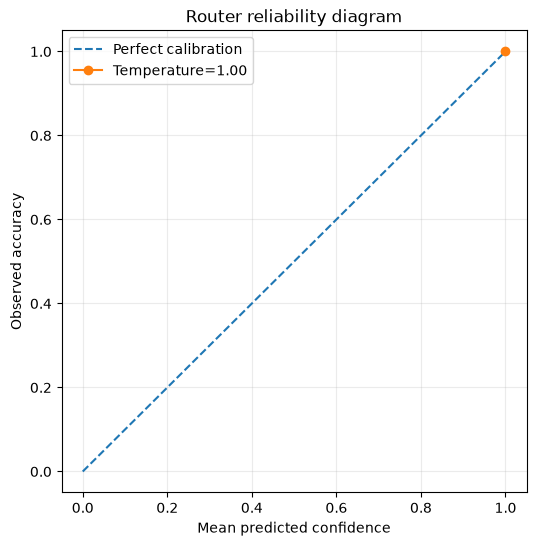

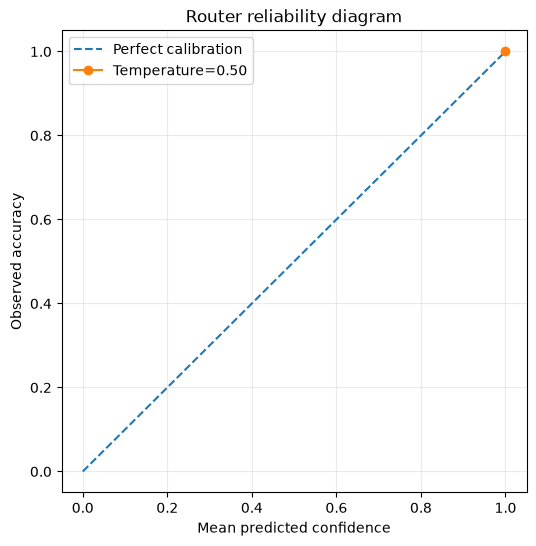

In [11]:
def plot_reliability_diagram(logits, labels, temperature=1.0, bins=10):
    """Plot mean confidence against empirical accuracy for confidence bins.

    Inputs: logits [N,C], labels [N], temperature, number of bins.
    Output: matplotlib figure displayed in the notebook.
    """
    probs = torch.softmax(logits.float() / temperature, dim=-1)
    confidence, predictions = probs.max(dim=-1)
    correct = predictions.eq(labels).float()
    edges = torch.linspace(0, 1, bins + 1)
    mean_conf, mean_acc = [], []
    for i in range(bins):
        mask = (confidence > edges[i]) & (confidence <= edges[i + 1])
        if mask.any():
            mean_conf.append(float(confidence[mask].mean()))
            mean_acc.append(float(correct[mask].mean()))

    plt.figure(figsize=(6, 6))
    plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
    plt.plot(mean_conf, mean_acc, marker="o", label=f"Temperature={temperature:.2f}")
    plt.xlabel("Mean predicted confidence")
    plt.ylabel("Observed accuracy")
    plt.title("Router reliability diagram")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()

plot_reliability_diagram(evaluation_logits, evaluation_labels, temperature=1.0)
plot_reliability_diagram(evaluation_logits, evaluation_labels, temperature=temperature)

## 9. Choose a confidence threshold and measure selective routing

The router will dispatch only when:
1. its most likely decision is classification or segmentation (not `clarify`); and
2. its calibrated maximum probability is at least the configured threshold.

Otherwise it abstains and asks for a clearer instruction.

A threshold creates a trade-off:
- higher threshold → fewer automatic dispatches (lower coverage), but accepted decisions may be more reliable;
- lower threshold → more automatic dispatches (higher coverage), but more uncertain decisions may pass through.

The threshold below is a starting point, not a universal constant. Choose it using calibration/evaluation results and the cost of a wrong dispatch in your application.

In [12]:
def selective_routing_metrics(logits, labels, temperature=1.0, threshold=0.70):
    """Measure coverage and accuracy among non-abstained clear-task requests.

    Inputs:
        logits: [N,3] router logits.
        labels: [N] ground-truth decision IDs.
        temperature: calibration temperature.
        threshold: minimum calibrated maximum probability for dispatch.
    Output:
        dictionary with overall coverage, clear-task coverage/accuracy,
        and ambiguous-request rejection rate.
    """
    probs = torch.softmax(logits.float() / temperature, dim=-1)
    confidence, predicted = probs.max(dim=-1)
    accepted = (predicted != DECISION_CLARIFY) & (confidence >= threshold)
    clear = labels != DECISION_CLARIFY
    ambiguous = labels == DECISION_CLARIFY

    clear_accepted = accepted & clear
    ambiguous_rejected = (~accepted) & ambiguous
    return {
        "overall_dispatch_coverage": float(accepted.float().mean()),
        "clear_task_coverage": float(clear_accepted.sum() / clear.sum().clamp_min(1)),
        "accepted_clear_task_accuracy": (
            float((predicted[clear_accepted] == labels[clear_accepted]).float().mean())
            if clear_accepted.any() else float("nan")
        ),
        "ambiguous_rejection_rate": (
            float(ambiguous_rejected.sum() / ambiguous.sum().clamp_min(1))
        ),
    }

CONFIDENCE_THRESHOLD = 0.70
for threshold in [0.50, 0.60, 0.70, 0.80, 0.90]:
    print(
        f"threshold={threshold:.2f}:",
        selective_routing_metrics(
            evaluation_logits, evaluation_labels, temperature, threshold
        )
    )

print("\\nSelected operating threshold:", CONFIDENCE_THRESHOLD)
print(selective_routing_metrics(
    evaluation_logits, evaluation_labels, temperature, CONFIDENCE_THRESHOLD
))

threshold=0.50: {'overall_dispatch_coverage': 0.6666666865348816, 'clear_task_coverage': 1.0, 'accepted_clear_task_accuracy': 1.0, 'ambiguous_rejection_rate': 1.0}
threshold=0.60: {'overall_dispatch_coverage': 0.6666666865348816, 'clear_task_coverage': 1.0, 'accepted_clear_task_accuracy': 1.0, 'ambiguous_rejection_rate': 1.0}
threshold=0.70: {'overall_dispatch_coverage': 0.6666666865348816, 'clear_task_coverage': 1.0, 'accepted_clear_task_accuracy': 1.0, 'ambiguous_rejection_rate': 1.0}
threshold=0.80: {'overall_dispatch_coverage': 0.6666666865348816, 'clear_task_coverage': 1.0, 'accepted_clear_task_accuracy': 1.0, 'ambiguous_rejection_rate': 1.0}
threshold=0.90: {'overall_dispatch_coverage': 0.6666666865348816, 'clear_task_coverage': 1.0, 'accepted_clear_task_accuracy': 1.0, 'ambiguous_rejection_rate': 1.0}
\nSelected operating threshold: 0.7
{'overall_dispatch_coverage': 0.6666666865348816, 'clear_task_coverage': 1.0, 'accepted_clear_task_accuracy': 1.0, 'ambiguous_rejection_rate': 1

## 10. Expert confidence: a separate quality signal

Once the router selects a task, we can inspect the selected YOLO expert's output confidence.

- **Classification:** use `result.probs.top1conf`.
- **Segmentation:** use the maximum confidence among detected instances (`result.boxes.conf`). If no instance is detected, report zero and flag the result for review.

These are raw model scores. They are not guaranteed to be calibrated probabilities, and classification confidence must not be numerically compared with segmentation detection confidence. A segmentation detection score also does not measure mask IoU or boundary quality.

For a serious deployment, choose the expert thresholds using a labelled validation set and measure classification accuracy or segmentation IoU/mAP separately.

In [13]:
from ultralytics import YOLO

class ConfidenceAwareYOLOMoE:
    """Run calibrated three-way routing and inspect the selected YOLO output.

    Why this class matters:
        It is the Stage 2 inference system. It can dispatch to a specialist,
        abstain when the task is unclear/uncertain, and flag low-confidence
        specialist outputs for human review.

    Constructor inputs:
        router: trained CLIPConfidenceRouter.
        cls_weights_path: path to the YOLO classification .pt checkpoint.
        seg_weights_path: path to the YOLO segmentation .pt checkpoint.
        temperature: positive scalar fitted on held-out calibration data.
        routing_threshold: minimum calibrated gate confidence for dispatch.
        cls_conf_threshold: task-specific raw YOLO classification score threshold.
        seg_conf_threshold: task-specific raw YOLO instance score threshold.
        device: torch device for router and expert inference.

    predict() inputs:
        image: file path, PIL image, or RGB tensor [3,H,W] in [0,1].
        prompt: natural-language task request.
        yolo_conf: detection threshold passed to Ultralytics.

    predict() output:
        dictionary containing routing probabilities, route/abstention reason,
        expert confidence and review flag. 'result' is the raw Ultralytics result
        for accepted requests, and None when the router abstains.
    """
    def __init__(self, router, cls_weights_path, seg_weights_path,
                 temperature=1.0, routing_threshold=0.70,
                 cls_conf_threshold=0.50, seg_conf_threshold=0.50,
                 device=DEVICE):
        """Load router and experts, then store calibration and review thresholds.

        Inputs: three model objects/paths, scalar temperature and thresholds,
        and a PyTorch device. Output: ready-to-use confidence-aware MoE wrapper.
        """
        self.device = torch.device(device)
        self.router = router.to(self.device).eval()
        self.cls_expert = YOLO(str(cls_weights_path))
        self.seg_expert = YOLO(str(seg_weights_path))
        self.temperature = float(temperature)
        self.routing_threshold = float(routing_threshold)
        self.cls_conf_threshold = float(cls_conf_threshold)
        self.seg_conf_threshold = float(seg_conf_threshold)

    @staticmethod
    def _to_pil(image):
        """Convert a file path, PIL image, or RGB float tensor to RGB PIL.

        Input: path/string, PIL image, or tensor [3,H,W] in [0,1].
        Output: RGB PIL image used by Ultralytics.
        """
        if isinstance(image, (str, Path)):
            return Image.open(image).convert("RGB")
        if isinstance(image, Image.Image):
            return image.convert("RGB")
        if torch.is_tensor(image) and image.ndim == 3 and image.shape[0] == 3:
            arr = (image.detach().cpu().clamp(0, 1).permute(1, 2, 0).numpy()
                   * 255).round().astype(np.uint8)
            return Image.fromarray(arr).convert("RGB")
        raise TypeError("image must be a path, PIL image, or [3,H,W] tensor")

    @torch.inference_mode()
    def predict(self, image, prompt, yolo_conf=0.25):
        """Make a confidence-aware routing decision and optionally run an expert.

        Inputs: image, prompt string, and Ultralytics confidence threshold.
        Output: structured dictionary. The method abstains before expert execution
        when the gate predicts clarify or its calibrated confidence is too low.
        """
        pil_image = self._to_pil(image)
        resized = pil_image.resize((224, 224), Image.Resampling.BICUBIC)
        arr = np.asarray(resized, dtype=np.float32) / 255.0
        tensor = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(self.device)

        output = self.router(tensor, [prompt])
        logits = output["logits"]
        probabilities = torch.softmax(logits / self.temperature, dim=-1)[0]
        decision_id = int(probabilities.argmax().item())
        gate_confidence = float(probabilities.max().item())
        probability_dict = {
            DECISION_NAMES[i]: float(probabilities[i].item()) for i in range(3)
        }

        if decision_id == DECISION_CLARIFY:
            return {
                "status": "abstained",
                "route": "clarify",
                "reason": "The gate classified the instruction as ambiguous.",
                "gate_confidence": gate_confidence,
                "routing_probabilities": probability_dict,
                "needs_review": True,
                "result": None,
            }

        if gate_confidence < self.routing_threshold:
            return {
                "status": "abstained",
                "route": "clarify",
                "reason": (
                    f"Gate confidence {gate_confidence:.3f} is below threshold "
                    f"{self.routing_threshold:.3f}."
                ),
                "gate_confidence": gate_confidence,
                "routing_probabilities": probability_dict,
                "needs_review": True,
                "result": None,
            }

        yolo_device = get_ultralytics_device(self.device)
        if decision_id == DECISION_CLASSIFICATION:
            result = self.cls_expert.predict(
                pil_image, device=yolo_device, conf=yolo_conf, verbose=False
            )[0]
            if result.probs is None:
                raise RuntimeError("Classification expert returned no class probabilities.")
            expert_confidence = float(result.probs.top1conf.item())
            top_id = int(result.probs.top1)
            return {
                "status": "completed",
                "route": "classification",
                "gate_confidence": gate_confidence,
                "routing_probabilities": probability_dict,
                "expert_confidence": expert_confidence,
                "top1_class_id": top_id,
                "top1_class_name": result.names[top_id],
                "needs_review": expert_confidence < self.cls_conf_threshold,
                "review_reason": (
                    "Classification confidence is below its configured threshold."
                    if expert_confidence < self.cls_conf_threshold else None
                ),
                "result": result,
            }

        result = self.seg_expert.predict(
            pil_image, device=yolo_device, conf=yolo_conf, verbose=False
        )[0]
        if result.boxes is None or len(result.boxes) == 0:
            scores = []
        else:
            scores = result.boxes.conf.detach().cpu().tolist()
        expert_confidence = max(scores) if scores else 0.0
        instance_count = len(scores)
        has_masks = result.masks is not None
        needs_review = (not has_masks) or (expert_confidence < self.seg_conf_threshold)
        return {
            "status": "completed",
            "route": "segmentation",
            "gate_confidence": gate_confidence,
            "routing_probabilities": probability_dict,
            "expert_confidence": float(expert_confidence),
            "num_instances": instance_count,
            "has_masks": has_masks,
            "needs_review": needs_review,
            "review_reason": (
                "No segmentation mask was returned."
                if not has_masks else
                "Segmentation instance confidence is below its configured threshold."
                if expert_confidence < self.seg_conf_threshold else None
            ),
            "result": result,
        }

print("Confidence-aware inference wrapper defined.")

Confidence-aware inference wrapper defined.


## 11. Evaluate the end-to-end routing policy

The gate evaluation and the expert evaluation answer different questions:

- **Gate:** did it choose classification, segmentation, or clarification correctly?
- **Expert:** once called, how good was its task-specific prediction?

The following summary evaluates the gate's selective behavior. It does not claim that a high YOLO confidence means a correct breed or a good segmentation mask.

In [14]:
# Summarize three-way decisions on the held-out evaluation logits.
eval_probs = torch.softmax(evaluation_logits / temperature, dim=-1)
eval_confidence, eval_predictions = eval_probs.max(dim=-1)
eval_accepted = (
    (eval_predictions != DECISION_CLARIFY) &
    (eval_confidence >= CONFIDENCE_THRESHOLD)
)

for decision_id, decision_name in DECISION_NAMES.items():
    mask = evaluation_labels == decision_id
    if mask.any():
        predicted_counts = {
            name: int((eval_predictions[mask] == idx).sum())
            for idx, name in DECISION_NAMES.items()
        }
        print(f"True {decision_name:14s} | n={int(mask.sum()):4d} | predictions={predicted_counts}")

print("\\nOverall evaluation accuracy:",
      float((eval_predictions == evaluation_labels).float().mean()))
print("Accepted dispatches:", int(eval_accepted.sum()), "/", len(eval_accepted))
print("Abstention rate:", float((~eval_accepted).float().mean()))

True classification | n=1835 | predictions={'classification': 1835, 'segmentation': 0, 'clarify': 0}
True segmentation   | n=1835 | predictions={'classification': 0, 'segmentation': 1835, 'clarify': 0}
True clarify        | n=1835 | predictions={'classification': 0, 'segmentation': 0, 'clarify': 1835}
\nOverall evaluation accuracy: 1.0
Accepted dispatches: 3670 / 5505
Abstention rate: 0.3333333432674408


## 12. Save the Stage 2 checkpoint and routing configuration

The new router is saved separately as `router_confidence_aware.pt`. Your Stage 1 router and both YOLO expert files remain untouched.

The checkpoint includes:
- the three-way router state;
- CLIP model/pretrained identifiers;
- learned temperature;
- routing confidence threshold;
- expert-specific review thresholds;
- decision ID mapping.

Keep this file together with the two original YOLO `.pt` checkpoints.

In [15]:
STAGE2_ROUTER_PATH = ARTIFACT_DIR / "router_confidence_aware.pt"
STAGE2_CONFIG_PATH = ARTIFACT_DIR / "moe_confidence_config.json"

torch.save({
    "model_state_dict": router.state_dict(),
    "clip_model_name": router.clip_model_name,
    "clip_pretrained": router.clip_pretrained,
    "hidden_dim": 256,
    "dropout": 0.1,
    "temperature": temperature,
    "routing_threshold": CONFIDENCE_THRESHOLD,
    "cls_conf_threshold": 0.50,
    "seg_conf_threshold": 0.50,
    "decision_names": DECISION_NAMES,
    "stage": 2,
}, STAGE2_ROUTER_PATH)

config = {
    "architecture": "confidence_aware_multimodal_hard_routing_moe",
    "stage": 2,
    "router_checkpoint": STAGE2_ROUTER_PATH.name,
    "experts": {
        "0": {"task": "classification", "checkpoint": CLS_WEIGHTS_PATH.name},
        "1": {"task": "segmentation", "checkpoint": SEG_WEIGHTS_PATH.name},
    },
    "decision_2": "clarify_or_abstain_not_an_expert",
    "temperature": temperature,
    "routing_threshold": CONFIDENCE_THRESHOLD,
    "expert_confidence_thresholds": {
        "classification": 0.50,
        "segmentation": 0.50,
    },
}
STAGE2_CONFIG_PATH.write_text(json.dumps(config, indent=2), encoding="utf-8")

print("Saved:", STAGE2_ROUTER_PATH)
print("Saved:", STAGE2_CONFIG_PATH)

Saved: /Users/christy.manthara/repositories/MoE-cls-seg/yolo_moe_project/artifacts/router_confidence_aware.pt
Saved: /Users/christy.manthara/repositories/MoE-cls-seg/yolo_moe_project/artifacts/moe_confidence_config.json


## 13. Run confidence-aware inference

The examples below show the three expected behaviors:
- a clear classification request;
- a clear segmentation request;
- an ambiguous request that should be sent to clarification rather than forced through an expert.

The exact probabilities depend on training, calibration, and prompt wording. If an ambiguous example is dispatched, add more representative ambiguous prompts and review the threshold.

In [16]:
from IPython.display import display

moe = ConfidenceAwareYOLOMoE(
    router=router,
    cls_weights_path=CLS_WEIGHTS_PATH,
    seg_weights_path=SEG_WEIGHTS_PATH,
    temperature=temperature,
    routing_threshold=CONFIDENCE_THRESHOLD,
    cls_conf_threshold=0.50,
    seg_conf_threshold=0.50,
    device=DEVICE,
)

demo_image, _ = test_base[0]
demo_prompts = [
    "Please classify the breed of this pet.",
    "Please segment the pet from the background.",
    "Can you help me understand this picture?",
]

for prompt in demo_prompts:
    prediction = moe.predict(demo_image, prompt)
    printable = {key: value for key, value in prediction.items() if key != "result"}
    print("\\nPrompt:", prompt)
    print(printable)

\nPrompt: Please classify the breed of this pet.
{'status': 'completed', 'route': 'classification', 'gate_confidence': 0.9999997615814209, 'routing_probabilities': {'classification': 0.9999997615814209, 'segmentation': 1.7934248909839097e-19, 'clarify': 2.098016835816452e-07}, 'expert_confidence': 0.768686056137085, 'top1_class_id': 36, 'top1_class_name': 'Yorkshire Terrier', 'needs_review': False, 'review_reason': None}
\nPrompt: Please segment the pet from the background.
{'status': 'completed', 'route': 'segmentation', 'gate_confidence': 0.9998961687088013, 'routing_probabilities': {'classification': 4.4167689389760026e-14, 'segmentation': 0.9998961687088013, 'clarify': 0.00010387758811702952}, 'expert_confidence': 0.6637564301490784, 'num_instances': 1, 'has_masks': True, 'needs_review': False, 'review_reason': None}
\nPrompt: Can you help me understand this picture?
{'status': 'abstained', 'route': 'clarify', 'reason': 'The gate classified the instruction as ambiguous.', 'gate_con

## 14. Visualize a segmentation result

This helper displays the original image and overlays the predicted instance masks when the router dispatches to segmentation. If the gate abstains or selects classification, the visualization reports that no segmentation result is available.

A missing mask is not proof that the gate failed: the gate may have correctly abstained, or the segmentation expert may have found no instance above its detection threshold.

In [17]:
import cv2

def show_stage2_segmentation(image, prediction):
    """Visualize YOLO segmentation masks returned by Stage 2 inference.

    Inputs:
        image: file path, PIL image, or RGB tensor supported by the MoE wrapper.
        prediction: dictionary returned by ConfidenceAwareYOLOMoE.predict().
    Output:
        matplotlib figure with image and optional predicted mask overlay.
    """
    pil = ConfidenceAwareYOLOMoE._to_pil(image)
    image_array = np.asarray(pil)
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(image_array)
    axes[0].set_title("Input")
    axes[0].axis("off")
    axes[1].imshow(image_array)

    result = prediction.get("result")
    if prediction.get("route") == "segmentation" and result is not None and result.masks is not None:
        masks = result.masks.data.detach().cpu().numpy()
        combined = masks.max(axis=0) > 0.5
        combined = cv2.resize(
            combined.astype(np.uint8), (image_array.shape[1], image_array.shape[0]),
            interpolation=cv2.INTER_NEAREST
        )
        axes[1].imshow(np.ma.masked_where(combined == 0, combined), alpha=0.5, cmap="cool")
        axes[1].set_title("Predicted segmentation")
    else:
        axes[1].set_title(f"No segmentation output ({prediction.get('route')})")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()

# Example:
# seg_result = moe.predict(demo_image, "Segment the pet from the background.")
# show_stage2_segmentation(demo_image, seg_result)

## 15. Use the Stage 2 model outside the notebook

The companion file `moe_confidence_inference.py` contains the inference classes and loader. Copy it beside your project or add its directory to `PYTHONPATH`.

Example:

```python
from moe_confidence_inference import load_confidence_moe

model = load_confidence_moe("./yolo_moe_project/artifacts")
prediction = model.predict(
    "./my_pet.jpg",
    "Segment the pet from the background."
)
print({key: value for key, value in prediction.items() if key != "result"})
```

The loader automatically selects CUDA, Apple MPS, or CPU. You can override the device if necessary.

## 16. Important limitations and next experiments

1. **Synthetic ambiguity labels:** the clarification prompts are hand-written templates. Add real ambiguous, contradictory, unsupported, and out-of-domain requests before relying on this behavior.
2. **Softmax confidence is not an OOD detector:** a model can be highly confident on an unfamiliar prompt. Test paraphrases and out-of-domain examples.
3. **Calibration data matters:** Stage 1 used the Oxford test split for checkpoint selection. This Stage 2 notebook divides that same split into calibration and evaluation subsets for a learning demonstration, but the evaluation is not a pristine independent benchmark. For a publishable result, reserve a new untouched test set and do not use it for model selection or calibration.
4. **Expert scores are task-specific:** classification top-1 confidence and segmentation detection confidence are different quantities. Do not compare them to decide which task the user intended.
5. **Measure actual task quality:** report classification accuracy and segmentation mAP/IoU separately. Confidence alone is not accuracy.
6. **Threshold selection is application-dependent:** raise the routing threshold when wrong dispatches are costly; lower it when coverage is more important.

### What Stage 2 adds

You now have a multimodal hard-routing MoE with a learned clarification option, temperature-scaled gate probabilities, selective dispatch, and task-specific expert confidence checks. This is a natural next step before exploring confidence-based expert selection among multiple experts that can solve the *same* task.